# RQ2 procedure: from profiling traces to a validated CBS budget — video decoder

One notebook per workload, identical code; only the configuration cell changes. Run it top to bottom. Every section does one thing.

| # | Section | Output |
|---|---|---|
| 0 | Configuration and helpers | |
| 1 | Load the runs, simple statistics of C, R, W | tables and tail plot |
| 2 | Feasibility: is $N\cdot p \ge 10$? | which tolerances the empirical bound supports |
| 3 | Tail bound $C_p$ of every run | empirical upper bound with confidence |
| 4 | Factors: $\alpha_{drift}$, $\alpha_{cores}$, $\alpha_{platform}$ | inflation factors |
| 5 | Budgets: Route 1, Route 2, Route 3 | $Q^*$ per scenario, route, p; written to `budgets/` |
| 6 | Offline validation on held-out runs | pass / fail per route and p |
| 7 | Online validation under KubeDeadline | quality metrics per cell |
| 8 | Recalibration | $Q_1$ and the next budgets file |
| 9 | Replay on recorded online runs | the whole loop tested on data we already have |

**Notation.** C = CPU time of a job (`cpu_ns`), R = response time (`response_ns`), W = dispatch wait (`wait_ns`), T = period = deadline, Q = budget,
p = tolerance, the admissible probability that a job's C exceeds its budget: $P(C > Q) \le p$. $C_p$ = the $(1-p)$ quantile of C (with an upper confidence bound).

In [ ]:
from pathlib import Path

# ======================== EDIT HERE (the only cell that changes between workloads) ========================
ROOT      = Path("..")        # folder with results/ (profiling) and alpha_drift/ (other VMs)
WORKLOAD  = "workload1"
PERIOD_MS = 41.667                            # period = deadline T
SCENARIOS = {"single_core": ["instance0"], "multi_core": ["instance0", "instance1"]}   # scenario -> instances

CONDITIONS = ["baseline1", "cache", "memory", "baseline2"]   # profiling session (folders in ROOT/results/<scenario>/)
BASELINES, STRESS = ["baseline1", "baseline2"], ["cache", "memory"]
DRIFT_VMS = ["worker6", "worker7"]            # other VMs of the same type (ROOT/alpha_drift/results/<vm>/<scenario>/baseline|cache|memory)

P_LIST = [1e-1, 1e-2, 1e-3]                   # tolerances: admissible P(C > Q)
CONF   = 0.95                                 # confidence of every upper bound
NP_MIN = 10                                   # an empirical bound at p needs N*p >= NP_MIN, otherwise: fall back to Route 3 (HWM)
HWM_P  = 1e-3                                 # p at which Route 3 takes alpha_drift

ALPHA_PLATFORM = {1: 1.03, 2: 1.06, 3: 1.11}  # alpha_platform(m) measured once per VM type with the synthetic victims, m = enemy cores
M_USED = {"single_core": 3, "multi_core": 2}  # m used per scenario
ADMISSION_MAX = 0.95                          # budget Q/T above this is not admitted

L_BOOT, N_BOOT = 1000, 200                    # moving-block bootstrap: block length (jobs), replicates
GAP_JOBS = 50                                 # overruns closer than this (jobs) count as one cluster
K_LIST = [10, 100]                            # window lengths for the (m,k) metric
K_MAX = 2                                     # maximum number of recalibrations

INTERFERENCES = ["none", "memory"]             # online runs per budget: without interference, with the memory enemy (add "cache" if the cache runs are done)
ITER = 0                                      # 0 = first budgets; set to 1 after recalibrating, etc.
OUT_DIR = Path("budgets")                     # where the budgets of each iteration are written
BUDGETS_FILE  = OUT_DIR / f"budgets_{WORKLOAD}_iter{ITER}.csv"   # written by section 5 (the budgets to give to KubeDeadline)
ONLINE_BUDGETS = BUDGETS_FILE                 # budgets the online runs actually used (read by section 7); point it at older runs to look at them
VALID_RESULTS = ROOT/ "workload1" / "validation_p2" / f"iter{ITER}" / "results"   # online runs: <scenario>/<route>/<ptag>_<none|memory|cache>/instance*.csv
REPLAY_RESULTS = ROOT / "validation" / "results"                         # already recorded online runs, replayed counterfactually in section 9

In [20]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom, beta

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", "{:.3f}".format)
ALPHA = 1 - CONF

def read_run(path):
    """one CSV: warm-up jobs removed, in job order"""
    df = pd.read_csv(path, usecols=["job_id", "cpu_ns", "response_ns", "wait_ns", "deadline_met", "skipped", "warmup"])
    return df[df.warmup == 0].sort_values("job_id").reset_index(drop=True)

def cp_upper(k, n):
    """Clopper-Pearson one-sided upper bound of a probability seen k times in n trials"""
    return 1.0 if k >= n else float(beta.ppf(1 - ALPHA, k + 1, n - k))

def os_ucb(xs, p):
    """order-statistic upper bound of the (1-p) quantile: x_(j), j = smallest rank with Binom(N, 1-p).cdf(j-1) >= CONF. NaN if j > N (N*p too small)"""
    n = len(xs)
    j = int(binom.ppf(CONF, n, 1 - p)) + 1
    return xs[j - 1] if j <= n else np.nan

def boot_ucb(x, ps):
    """moving-block bootstrap upper bound of the (1-p) quantile (keeps the clustering of the jobs)"""
    n = len(x); nb = n // L_BOOT
    if nb < 2:
        return np.full(len(ps), np.nan)
    rng = np.random.default_rng(0); q = np.empty((N_BOOT, len(ps)))
    for b in range(N_BOOT):
        starts = rng.integers(0, n - L_BOOT + 1, nb)
        q[b] = np.quantile(x[(starts[:, None] + np.arange(L_BOOT)).ravel()], [1 - p for p in ps])
    return np.quantile(q, CONF, axis=0)

def bound_table(x, ps):
    """C_p of a series x (ms): point estimate, the two upper bounds, and ucb = the larger one (NaN if N*p < NP_MIN)"""
    xs = np.sort(x)
    os_ = np.array([os_ucb(xs, p) for p in ps]); bt = boot_ucb(x, ps)
    ok = np.array([len(x) * p >= NP_MIN for p in ps])
    ucb = np.where(ok & ~np.isnan(os_), np.fmax(os_, bt), np.nan)
    return pd.DataFrame(dict(p=ps, point=np.quantile(x, [1 - p for p in ps]), orderstat=os_, block_boot=bt, ucb=ucb)).set_index("p")

def exceed_test(x, Q, p):
    """overruns x > Q: rate, number of clusters, upper bound of P(C>Q) = CP upper bound of clusters/N times the mean cluster size, and ucb <= p"""
    if np.isnan(Q):
        return np.nan, 0, np.nan, False
    idx = np.flatnonzero(x > Q); n = len(x)
    if len(idx) == 0:
        return 0.0, 0, cp_upper(0, n), cp_upper(0, n) <= p
    ncl = 1 + int(np.sum(np.diff(idx) > GAP_JOBS))
    ucb = cp_upper(ncl, n) * len(idx) / ncl
    return len(idx) / n, ncl, ucb, ucb <= p

def longest_run(b):
    """longest streak of True"""
    if not b.any():
        return 0
    edges = np.flatnonzero(np.diff(np.r_[0, b.astype(int), 0]))
    return int((edges[1::2] - edges[::2]).max())

def window_max(b, k):
    """worst number of True in any window of k consecutive jobs"""
    return int(np.convolve(b.astype(int), np.ones(k, int), "valid").max()) if len(b) >= k else int(b.sum())

def ptag(p):
    return "all" if p is None else "p1e-%d" % round(-math.log10(p))

## 1. Load the runs and simple statistics

Runs: the **profiling session** (`baseline1 → cache → memory → baseline2`, in `ROOT/results/`) and the runs on **other VMs** of the same type (`ROOT/alpha_drift/results/<vm>/`, the swapped session).
Skipped jobs have no C, R or W and are left out of the statistics. Warm-up jobs are always removed.

In [21]:
runs = []
for scen in SCENARIOS:
    for cond in CONDITIONS:
        runs.append(dict(run=f"profiling_{cond}", group="profiling", vm="profiling", scen=scen, cond=cond,
                         kind="base" if cond in BASELINES else "stress", dir=ROOT / "results" / scen / cond))
    for vm in DRIFT_VMS:
        for cond, kind in [("baseline", "base")] + [(c, "stress") for c in STRESS]:
            runs.append(dict(run=f"drift_{vm}_{cond}", group="drift", vm=vm, scen=scen, cond=cond, kind=kind,
                             dir=ROOT / "alpha_drift" / "results" / vm / scen / cond))
runs = [r for r in runs if (r["dir"] / "instance0.csv").exists()]

data, series = {}, {}                        # data: all jobs of a run; series: C (ms) of the non-skipped jobs, in job order
for r in runs:
    for inst in SCENARIOS[r["scen"]]:
        f = r["dir"] / f"{inst}.csv"
        if f.exists():
            key = (r["run"], r["scen"], inst)
            data[key] = read_run(f)
            d = data[key]; series[key] = (d[d.skipped == 0].cpu_ns / 1e6).to_numpy()

inv = pd.DataFrame([dict(run=k[0], scenario=k[1], instance=k[2], jobs=len(data[k]), skipped=int((data[k].skipped == 1).sum()),
                         late=int(((data[k].skipped == 0) & (data[k].deadline_met == 0)).sum())) for k in data])
display(inv.set_index(["scenario", "run", "instance"]))

jobs  skipped  late
scenario    run                    instance                        
single_core profiling_baseline1    instance0  100000        0     0
            profiling_cache        instance0  100000       56     3
            profiling_memory       instance0  100000        0     0
            profiling_baseline2    instance0  100000        0     0
            drift_worker6_baseline instance0  100000        0     0
            drift_worker7_memory   instance0   50000        0     0
multi_core  profiling_baseline1    instance0  100000       71     1
                                   instance1  100000       71     1
            profiling_cache        instance0  100000        0     0
                                   instance1  100000        0     0
            profiling_memory       instance0  100000        0     0
                                   instance1  100000        0     0
            profiling_baseline2    instance0  100000        1     1
                                   instance1  100000        1     1
            drift_worker6_baseline instance0  100000        0     0
                                   instance1  100000        0     0
            drift_worker6_memory   instance0   50000       97     1
                                   instance1   50000       97     1

### 1.1 Distribution of C, R and W in the profiling session (ms)
`cv` = std / mean. The stressed runs show how much the tail moves; baseline1 and baseline2 show the drift inside one VM.

In [22]:
def describe(v):
    q = np.quantile(v, [.5, .9, .99, .999])
    return dict(n=len(v), mean=v.mean(), cv=v.std() / v.mean(), p50=q[0], p90=q[1], p99=q[2], p999=q[3], max=v.max())

COLS = dict(C="cpu_ns", R="response_ns", W="wait_ns")
rows = []
for r in runs:
    if r["group"] != "profiling":
        continue
    for inst in SCENARIOS[r["scen"]]:
        d = data[(r["run"], r["scen"], inst)]; d = d[d.skipped == 0]
        for name, col in COLS.items():
            rows.append(dict(scenario=r["scen"], instance=inst, condition=r["cond"], quantity=name, **describe(d[col] / 1e6)))
stats = pd.DataFrame(rows)
for name in COLS:
    print(f"--- {name} ---")
    display(stats[stats.quantity == name].drop(columns="quantity").set_index(["scenario", "instance", "condition"]))

--- C ---


n   mean    cv    p50    p90    p99   p999    max
scenario    instance  condition                                                        
single_core instance0 baseline1  100000 15.192 0.128 14.999 17.117 22.299 22.809 25.420
                      cache       99944 15.587 0.124 15.393 17.404 22.651 23.135 26.002
                      memory     100000 15.734 0.123 15.518 17.624 22.912 23.461 32.331
                      baseline2  100000 15.339 0.127 15.151 17.220 22.495 22.923 23.573
multi_core  instance0 baseline1   99929 15.150 0.124 14.961 16.989 22.086 22.493 26.341
            instance1 baseline1   99929 15.073 0.124 14.876 16.912 22.008 22.406 26.357
            instance0 cache      100000 15.318 0.122 15.117 17.132 22.239 22.686 25.597
            instance1 cache      100000 15.196 0.123 14.995 17.008 22.129 22.590 25.761
            instance0 memory     100000 14.954 0.125 14.757 16.725 21.874 22.292 22.922
            instance1 memory     100000 14.870 0.126 14.667 16.648 21.800 22.244 22.755
            instance0 baseline2   99999 14.551 0.130 14.359 16.356 21.459 21.900 24.613
            instance1 baseline2   99999 14.510 0.130 14.316 16.313 21.413 21.861 24.620

--- R ---


n   mean    cv    p50    p90    p99   p999      max
scenario    instance  condition                                                          
single_core instance0 baseline1  100000 15.421 0.126 15.229 17.356 22.519 23.052   29.662
                      cache       99944 15.842 0.308 15.627 17.644 22.876 23.393  990.192
                      memory     100000 15.960 0.121 15.751 17.859 23.112 23.696   38.716
                      baseline2  100000 15.558 0.125 15.373 17.447 22.700 23.155   33.138
multi_core  instance0 baseline1   99929 15.439 0.615 15.223 17.255 22.343 22.772 2958.588
            instance1 baseline1   99929 15.318 0.620 15.091 17.132 22.230 22.653 2958.526
            instance0 cache      100000 15.580 0.120 15.382 17.402 22.494 22.967   38.682
            instance1 cache      100000 15.408 0.122 15.207 17.225 22.344 22.834   38.629
            instance0 memory     100000 15.207 0.123 15.010 16.983 22.121 22.568   35.762
            instance1 memory     100000 15.071 0.125 14.866 16.854 22.006 22.481   35.899
            instance0 baseline2   99999 14.798 0.128 14.603 16.606 21.696 22.172   51.089
            instance1 baseline2   99999 14.712 0.129 14.512 16.515 21.621 22.107   51.043

--- W ---


n  mean     cv   p50   p90   p99  p999      max
scenario    instance  condition                                                      
single_core instance0 baseline1  100000 0.200  0.513 0.195 0.246 0.289 0.345   16.126
                      cache       99944 0.226 19.872 0.199 0.249 0.286 0.342  976.389
                      memory     100000 0.195  0.533 0.198 0.234 0.276 0.333   24.254
                      baseline2  100000 0.189  0.428 0.192 0.211 0.265 0.311   17.137
multi_core  instance0 baseline1   99929 0.265 35.175 0.245 0.256 0.268 0.316 2943.048
            instance1 baseline1   99929 0.216 43.110 0.186 0.203 0.253 0.275 2942.987
            instance0 cache      100000 0.238  0.679 0.247 0.258 0.270 0.315   22.447
            instance1 cache      100000 0.183  0.868 0.184 0.198 0.249 0.267   22.500
            instance0 memory     100000 0.232  0.691 0.240 0.252 0.264 0.303   20.938
            instance1 memory     100000 0.178  0.925 0.175 0.193 0.246 0.263   21.080
            instance0 baseline2   99999 0.226  0.868 0.234 0.246 0.258 0.305   37.587
            instance1 baseline2   99999 0.180  1.084 0.172 0.226 0.247 0.266   37.649

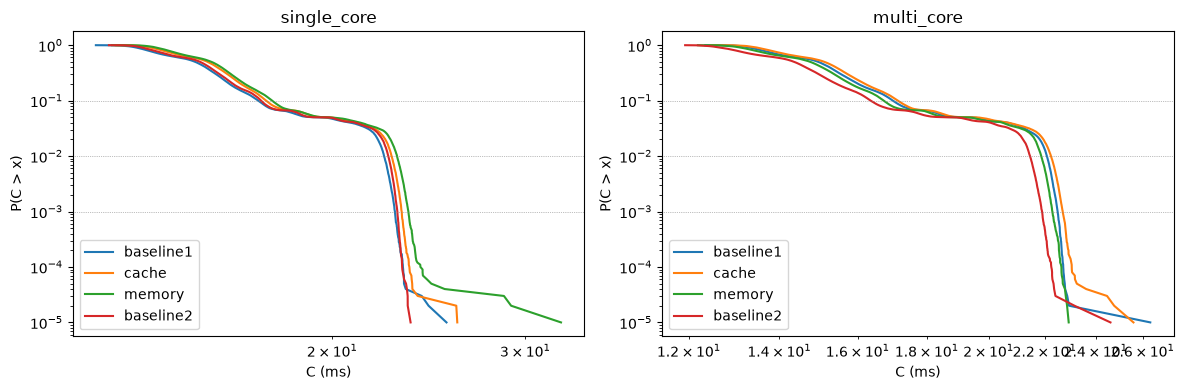

In [23]:
# survival function P(C > x) of instance0: the right end is the tail the budget has to cover
fig, axes = plt.subplots(1, len(SCENARIOS), figsize=(6 * len(SCENARIOS), 4), squeeze=False)
for ax, scen in zip(axes[0], SCENARIOS):
    for r in runs:
        key = (r["run"], scen, "instance0")
        if r["group"] == "profiling" and r["scen"] == scen:
            x = np.sort(series[key]); ax.loglog(x, 1 - np.arange(1, len(x) + 1) / len(x) + 1 / len(x), label=r["cond"])
    for p in P_LIST:
        ax.axhline(p, color="grey", lw=.5, ls=":")
    ax.set_title(scen); ax.set_xlabel("C (ms)"); ax.set_ylabel("P(C > x)"); ax.legend()
plt.tight_layout(); plt.show()

## 2. Feasibility: is $N\cdot p \ge 10$?

The empirical bound of the $(1-p)$ quantile needs enough jobs above it. With N jobs the expected number of jobs beyond the quantile is $N\cdot p$; we ask for $N\cdot p \ge 10$ (the order-statistic bound at 95% needs $N \gtrsim 3/p$ at the very least).
For a tolerance that does not meet it, the empirical Routes 1 and 2 are **not available** and the budget falls back to **Route 3 (high-water mark)**, or more data has to be collected.
EVT is not part of the procedure: a practitioner who wants it has to check its fit separately.

In [24]:
rows = [dict(scenario=k[1], run=k[0], instance=k[2], N=len(series[k]), **{f"N*p (p={p:g})": len(series[k]) * p for p in P_LIST}) for k in series]
feas = pd.DataFrame(rows)
display(feas.set_index(["scenario", "run", "instance"]))

feasible = {(scen, p): all(len(series[k]) * p >= NP_MIN for k in series if k[1] == scen) for scen in SCENARIOS for p in P_LIST}
print(pd.Series(feasible).unstack().rename_axis(index="scenario", columns="p").to_string())
print("\nFalse = N*p < %d in at least one run: Routes 1 and 2 fall back to Route 3 for that p." % NP_MIN)

N  N*p (p=0.1)  N*p (p=0.01)  N*p (p=0.001)
scenario    run                    instance                                                   
single_core profiling_baseline1    instance0  100000    10000.000      1000.000        100.000
            profiling_cache        instance0   99944     9994.400       999.440         99.944
            profiling_memory       instance0  100000    10000.000      1000.000        100.000
            profiling_baseline2    instance0  100000    10000.000      1000.000        100.000
            drift_worker6_baseline instance0  100000    10000.000      1000.000        100.000
            drift_worker7_memory   instance0   50000     5000.000       500.000         50.000
multi_core  profiling_baseline1    instance0   99929     9992.900       999.290         99.929
                                   instance1   99929     9992.900       999.290         99.929
            profiling_cache        instance0  100000    10000.000      1000.000        100.000
                                   instance1  100000    10000.000      1000.000        100.000
            profiling_memory       instance0  100000    10000.000      1000.000        100.000
                                   instance1  100000    10000.000      1000.000        100.000
            profiling_baseline2    instance0   99999     9999.900       999.990         99.999
                                   instance1   99999     9999.900       999.990         99.999
            drift_worker6_baseline instance0  100000    10000.000      1000.000        100.000
                                   instance1  100000    10000.000      1000.000        100.000
            drift_worker6_memory   instance0   49903     4990.300       499.030         49.903
                                   instance1   49903     4990.300       499.030         49.903

p            0.001  0.010  0.100
scenario                        
multi_core    True   True   True
single_core   True   True   True

False = N*p < 10 in at least one run: Routes 1 and 2 fall back to Route 3 for that p.


## 3. Tail bound $C_p$ of every run

For a run with N job times $x_1,\dots,x_N$ and tolerance p, $C_p$ is the $(1-p)$ quantile, bounded from above with confidence `CONF`:

- **order statistic:** the number of jobs below the true quantile follows $\mathrm{Binomial}(N, 1-p)$, so the sorted sample element $x_{(j)}$ with $j=\min\{j: F_{Bin}(j-1)\ge CONF\}$ is an upper bound. Valid for independent jobs.
- **moving-block bootstrap:** resample blocks of `L_BOOT` consecutive jobs and take the `CONF` quantile of the bootstrap quantiles. Keeps the clustering of slow jobs.
- **$C_p$ = the larger of the two** (`ucb`). NaN when $N\cdot p < $ `NP_MIN`.

The next cells use `ucb` only.

In [25]:
bnd = {k: bound_table(series[k], P_LIST) for k in series}
rows = [dict(scenario=k[1], instance=k[2], run=k[0], p=p, **bnd[k].loc[p].to_dict()) for k in bnd for p in P_LIST]
bt = pd.DataFrame(rows)
display(bt.pivot_table(index=["scenario", "instance", "run"], columns="p", values="ucb", sort=False))

p                                             0.100  0.010  0.001
scenario    instance  run                                        
single_core instance0 profiling_baseline1    17.144 22.327 22.851
                      profiling_cache        17.428 22.670 23.151
                      profiling_memory       17.652 22.933 23.507
                      profiling_baseline2    17.236 22.512 22.941
                      drift_worker6_baseline 16.635 21.822 22.448
                      drift_worker7_memory   16.507 21.692 22.351
multi_core  instance0 profiling_baseline1    17.005 22.103 22.515
                      profiling_cache        17.157 22.263 22.716
                      profiling_memory       16.739 21.891 22.328
                      profiling_baseline2    16.373 21.473 21.924
                      drift_worker6_baseline 16.502 21.629 22.274
                      drift_worker6_memory   17.003 22.019 22.433
            instance1 profiling_baseline1    16.931 22.031 22.428
                      profiling_cache        17.034 22.157 22.611
                      profiling_memory       16.664 21.819 22.260
                      profiling_baseline2    16.329 21.430 21.902
                      drift_worker6_baseline 16.535 21.649 22.271
                      drift_worker6_memory   17.038 22.049 22.467

## 4. Factors

### 4.1 $\alpha_{drift}$: variation of the bound between runs and VMs
Every baseline run of a scenario (the two profiling baselines and the baselines on the other VMs) gets its own $C_p$. With $C_p(r)$ the bound of run r:

$$\alpha_{drift}(p) = \frac{\max_r C_p(r)}{\min_r C_p(r)}$$

per instance; the deployment value is the worst instance. With n runs, a new run is covered with probability about $n/(n+1)$ (exchangeable runs), so n is reported: **few runs mean a weak guarantee**.
An episode inside one baseline is not removed: it enters the spread, which is what the factor is for.

In [26]:
rows = []
for scen, insts in SCENARIOS.items():
    names = [r["run"] for r in runs if r["scen"] == scen and r["kind"] == "base"]
    for inst in insts:
        for p in P_LIST:
            v = np.array([bnd[(n, scen, inst)].loc[p, "ucb"] for n in names if (n, scen, inst) in bnd])
            rows.append(dict(scenario=scen, instance=inst, p=p, n_runs=len(v), alpha=v.max() / v.min()))
spread = pd.DataFrame(rows)
alpha_drift = spread.groupby(["scenario", "p"]).agg(alpha=("alpha", "max"), n_runs=("n_runs", "min"))
alpha_drift["coverage n/(n+1)"] = alpha_drift.n_runs / (alpha_drift.n_runs + 1)
display(alpha_drift)

alpha  n_runs  coverage n/(n+1)
scenario    p                                     
multi_core  0.001  1.027       3             0.750
            0.010  1.029       3             0.750
            0.100  1.039       3             0.750
single_core 0.001  1.022       3             0.750
            0.010  1.032       3             0.750
            0.100  1.036       3             0.750

### 4.2 $\alpha_{cores}$ (stress) and $\alpha_{platform}$
- $\alpha_{cores}(p) = C_p^{stress} / C_p^{base}$ measured on the profiling VM, one value per stressor. It tells how much the stress moves the tail (reported; Route 1 already contains it).
- $\alpha_{platform}(m)$ is the factor of the synthetic victims (measured once per VM type, `ALPHA_PLATFORM`, m = number of enemy cores). Route 2 uses it in place of the stress profiling of the task.

In [27]:
def prof_runs(scen, kind):
    return [r["run"] for r in runs if r["scen"] == scen and r["group"] == "profiling" and r["kind"] == kind]

rows = []
for scen, insts in SCENARIOS.items():
    for inst in insts:
        for p in P_LIST:
            base = np.max([bnd[(n, scen, inst)].loc[p, "ucb"] for n in prof_runs(scen, "base")])
            for n in prof_runs(scen, "stress"):
                rows.append(dict(scenario=scen, instance=inst, p=p, stress=n.replace("profiling_", ""), alpha_cores=bnd[(n, scen, inst)].loc[p, "ucb"] / base))
ac = pd.DataFrame(rows)
display(ac.groupby(["scenario", "stress", "p"]).alpha_cores.max().unstack("p"))
print("alpha_platform used:", {s: (M_USED[s], ALPHA_PLATFORM[M_USED[s]]) for s in SCENARIOS}, "(scenario: (m, factor))")

p                   0.001  0.010  0.100
scenario    stress                     
multi_core  cache   1.009  1.007  1.009
            memory  0.993  0.990  0.984
single_core cache   1.009  1.007  1.011
            memory  1.025  1.019  1.024

alpha_platform used: {'single_core': (3, 1.11), 'multi_core': (2, 1.06)} (scenario: (m, factor))


## 5. Budgets

$C_p^{base}$ = largest bound of the two profiling baselines, $C_p^{stress}$ = largest bound over the stressed runs (cache, memory), per instance. One reservation serves all instances of a scenario, so the deployment budget $Q^*$ is the **maximum over the instances**.

| Route | Formula | Needs |
|---|---|---|
| 1 (full profiling) | $Q = C_p^{stress}\cdot\alpha_{drift}(p)$ | stress profiling of the task |
| 2 (baseline + platform factor) | $Q = C_p^{base}\cdot\alpha_{platform}(m)\cdot\alpha_{drift}(p)$ | baseline profiling only |
| 3 (high-water mark) | $Q = \max C^{stress}\cdot\alpha_{drift}(HWM_P)$, **one value for every p** | stress profiling; no tail estimate. Jobs with $C>2T$ (stalls) are left out of the maximum |

Rules applied after the formulas: (i) where $N\cdot p<10$ Route 1 and 2 are replaced by Route 3 (marked `*`); (ii) **monotone in p**: a stricter tolerance never gets a smaller budget than a looser one; (iii) admission: $Q/T \le$ `ADMISSION_MAX` for Routes 1 and 2, while **Route 3 is capped at `ADMISSION_MAX` $\cdot T$** (a high-water mark above that is useless): the cap is flagged `(capped)` and the share of stressed jobs left above it is printed.

In [28]:
def hwm_ms(scen, inst):
    return max(series[(n, scen, inst)][series[(n, scen, inst)] <= 2 * PERIOD_MS].max() for n in prof_runs(scen, "stress"))

def finalize(raw):
    """raw: scenario, route, p, Q_raw (ms) -> fallback to Route 3 where NaN, monotone envelope in p, Q/T, admission"""
    out = []
    for (scen, route), g in raw.groupby(["scenario", "route"], sort=False):
        g = g.sort_values("p", ascending=False).copy()                    # loosest tolerance first
        h = raw[(raw.scenario == scen) & (raw.route == "hwm")].Q_raw.iloc[0]
        g["fallback"] = g.Q_raw.isna() & (route != "hwm")
        g["Q_ms"] = g.Q_raw.fillna(h).cummax()                           # a stricter p is never cheaper
        out.append(g)
    out = pd.concat(out)
    out["Q_over_T"] = out.Q_ms / PERIOD_MS
    out["admitted"] = out.Q_over_T <= ADMISSION_MAX
    return out.reset_index(drop=True)

rows = []
for scen, insts in SCENARIOS.items():
    a_h = alpha_drift.loc[(scen, HWM_P), "alpha"]; a_h = 1.0 if np.isnan(a_h) else a_h
    q3_raw = max(hwm_ms(scen, i) for i in insts) * a_h
    q3 = min(q3_raw, ADMISSION_MAX * PERIOD_MS)                  # Route 3 is only useful if admissible: cap it at the largest admissible budget
    for p in P_LIST:
        a = alpha_drift.loc[(scen, p), "alpha"]
        q1, q2 = [], []
        for inst in insts:
            base = np.max([bnd[(n, scen, inst)].loc[p, "ucb"] for n in prof_runs(scen, "base")])
            stress = np.max([bnd[(n, scen, inst)].loc[p, "ucb"] for n in prof_runs(scen, "stress")])
            q1.append(stress * a); q2.append(base * ALPHA_PLATFORM[M_USED[scen]] * a)
        rows += [dict(scenario=scen, route="route1", p=p, Q_raw=np.max(q1)), dict(scenario=scen, route="route2b", p=p, Q_raw=np.max(q2)),
                 dict(scenario=scen, route="hwm", p=p, Q_raw=q3, hwm_capped=bool(q3_raw > q3))]
raw = pd.DataFrame(rows)
raw["hwm_capped"] = raw.hwm_capped.fillna(False).astype(bool)
bud = finalize(raw)

show = bud.assign(cell=lambda x: x.Q_ms.round(3).astype(str) + " (" + x.Q_over_T.round(3).astype(str) + ")" + np.where(x.fallback, "*", "") + np.where(x.hwm_capped, " (capped)", "") + np.where(x.admitted, "", " NOT ADMITTED"))
display(show.pivot_table(index=["scenario", "route"], columns="p", values="cell", aggfunc="first"))
print("cell = Q* in ms (Q*/T);  * = fallback to Route 3 because N*p < %d;  (capped) = Route 3 cut at ADMISSION_MAX * T" % NP_MIN)
for scen in SCENARIOS:                                                            # a capped Route 3 is not a high-water mark any more: show what it leaves uncovered
    g = bud[(bud.scenario == scen) & (bud.route == "hwm") & bud.hwm_capped]
    if len(g):
        c = np.concatenate([series[(n, scen, i)] for n in prof_runs(scen, "stress") for i in SCENARIOS[scen]])
        print(f"{scen}: Route 3 capped at {g.Q_ms.iloc[0]:.2f} ms; {np.mean(c > g.Q_ms.iloc[0]):.2e} of the stressed-run jobs are still above it")

p                             0.001           0.010           0.100
scenario    route                                                  
multi_core  hwm      26.456 (0.635)  26.456 (0.635)  26.456 (0.635)
            route1    23.329 (0.56)   22.916 (0.55)   17.82 (0.428)
            route2b   24.51 (0.588)  24.117 (0.579)  18.722 (0.449)
single_core hwm      33.041 (0.793)  33.041 (0.793)  33.041 (0.793)
            route1   24.023 (0.577)  23.657 (0.568)   18.29 (0.439)
            route2b  26.024 (0.625)  25.778 (0.619)  19.823 (0.476)

cell = Q* in ms (Q*/T);  * = fallback to Route 3 because N*p < 10;  (capped) = Route 3 cut at ADMISSION_MAX * T


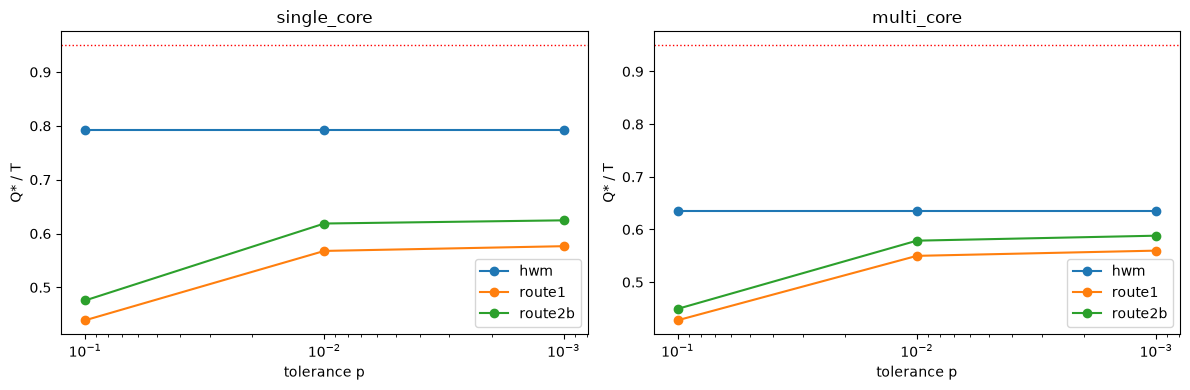

written budgets/budgets_workload1_iter0.csv


In [29]:
fig, axes = plt.subplots(1, len(SCENARIOS), figsize=(6 * len(SCENARIOS), 4), squeeze=False)
for ax, scen in zip(axes[0], SCENARIOS):
    for route, g in bud[bud.scenario == scen].groupby("route"):
        ax.plot(g.p, g.Q_over_T, "o-", label=route)
    ax.axhline(ADMISSION_MAX, color="red", ls=":", lw=1); ax.set_xscale("log"); ax.invert_xaxis()
    ax.set_title(scen); ax.set_xlabel("tolerance p"); ax.set_ylabel("Q* / T"); ax.legend()
plt.tight_layout(); plt.show()

# file for the validation driver: same format as validation/budgets.csv (Route 3 is one row, p = "all")
def export_budgets(table, path):
    OUT_DIR.mkdir(exist_ok=True)
    exp = table[(table.route != "hwm") | (table.p == HWM_P)].copy()
    exp["p"] = [("all" if r == "hwm" else p) for r, p in zip(exp.route, exp.p)]
    exp["runtime_us"] = (exp.Q_ms * 1000).round().astype(int); exp["period_us"] = round(PERIOD_MS * 1000)
    exp[["scenario", "route", "p", "Q_ms", "Q_over_T", "runtime_us", "period_us", "admitted"]].to_csv(path, index=False)

export_budgets(bud, BUDGETS_FILE)
print("written", BUDGETS_FILE)

## 6. Offline validation on held-out data

A budget is **valid on a held-out run** if its overrun probability $P(C>Q)$ is at most p, judged with the upper confidence bound of `exceed_test`:
overruns closer than `GAP_JOBS` jobs form one cluster, $P_{ucb} = CP_{upper}(\#clusters, N)\cdot(\text{mean cluster size})$, pass if $P_{ucb}\le p$.

- **6.1 Held-out baselines (leave one run out).** For each baseline run h except the reference (`baseline1`): $\alpha_{drift}$ from the **other** runs, $Q = C_p(\text{reference})\cdot\alpha_{drift}^{(-h)}$, applied to h. Tests whether the spread rule predicts a new run.
- **6.2 Held-out stressed runs.** The stressed runs on the other VMs are not used by any factor. The budgets of section 5 (Route 1 and 2) are applied to them.

In [30]:
ref = "profiling_baseline1"
rows = []
for scen, insts in SCENARIOS.items():
    names = [r["run"] for r in runs if r["scen"] == scen and r["kind"] == "base"]
    for h in names:
        if h == ref:
            continue
        for inst in insts:
            for p in P_LIST:
                c_ref = bnd[(ref, scen, inst)].loc[p, "ucb"]
                v = np.array([bnd[(n, scen, inst)].loc[p, "ucb"] for n in names if n != h])
                Q = c_ref * v.max() / v.min()                                   # before: spread of the OTHER runs
                rate, ncl, ucb, ok = exceed_test(series[(h, scen, inst)], Q, p)
                Q1 = max(Q, c_ref * alpha_drift.loc[(scen, p), "alpha"])        # after: alpha_drift of 4.1 (all runs, h included)
                rate1, ncl1, ucb1, ok1 = exceed_test(series[(h, scen, inst)], Q1, p)
                rows.append(dict(scenario=scen, held_out=h, instance=inst, p=p, Q_ms=Q, overrun_rate=rate, clusters=ncl, P_ucb=ucb, passed=ok,
                                 Q1_ms=Q1, overrun_rate1=rate1, clusters1=ncl1, P_ucb1=ucb1, passed1=ok1))
loo = pd.DataFrame(rows)
display(loo.set_index(["scenario", "held_out", "instance", "p"]))
print(loo.groupby(["scenario", "p"]).agg(tests=("passed", "size"), passed_before=("passed", "sum"), passed_after=("passed1", "sum")).to_string())
print("\n'after' uses alpha_drift WITH the held-out run: a consistency check, not an independent validation (see 6.3).")

Q_ms  overrun_rate  clusters  P_ucb  passed  Q1_ms  overrun_rate1  clusters1  P_ucb1  passed1
scenario    held_out               instance  p                                                                                                    
single_core profiling_baseline2    instance0 0.100 17.669         0.071       834  0.075    True 17.764          0.069        834   0.073     True
                                             0.010 22.843         0.002       135  0.002    True 23.033          0.000         32   0.000     True
                                             0.001 23.262         0.000         5  0.000    True 23.353          0.000          4   0.000     True
            drift_worker6_baseline instance0 0.100 17.236         0.070       837  0.074    True 17.764          0.065        835   0.069     True
                                             0.010 22.512         0.001        35  0.001    True 23.033          0.000          7   0.000     True
                                             0.001 22.941         0.000         7  0.000    True 23.353          0.000          7   0.000     True
multi_core  profiling_baseline2    instance0 0.100 17.524         0.064       834  0.068    True 17.662          0.061        834   0.065     True
                                             0.010 22.587         0.000         2  0.000    True 22.751          0.000          2   0.000     True
                                             0.001 22.759         0.000         2  0.000    True 23.123          0.000          2   0.000     True
                                   instance1 0.100 17.337         0.066       834  0.070    True 17.585          0.062        834   0.065     True
                                             0.010 22.419         0.000         2  0.000    True 22.677          0.000          2   0.000     True
                                             0.001 22.586         0.000         2  0.000    True 23.033          0.000          1   0.000     True
            drift_worker6_baseline instance0 0.100 17.662         0.065       835  0.069    True 17.662          0.065        835   0.069     True
                                             0.010 22.751         0.000        11  0.000    True 22.751          0.000         11   0.000     True
                                             0.001 23.123         0.000         7  0.000    True 23.123          0.000          7   0.000     True
                                   instance1 0.100 17.556         0.067       836  0.071    True 17.585          0.067        836   0.071     True
                                             0.010 22.648         0.000        12  0.001    True 22.677          0.000         11   0.000     True
                                             0.001 22.966         0.000         8  0.000    True 23.033          0.000          8   0.000     True

                   tests  passed_before  passed_after
scenario    p                                        
multi_core  0.001      4              4             4
            0.010      4              4             4
            0.100      4              4             4
single_core 0.001      2              2             2
            0.010      2              2             2
            0.100      2              2             2

'after' uses alpha_drift WITH the held-out run: a consistency check, not an independent validation (see 6.3).


In [31]:
rows = []
for r in runs:
    if not (r["group"] == "drift" and r["kind"] == "stress"):
        continue
    for inst in SCENARIOS[r["scen"]]:
        key = (r["run"], r["scen"], inst)
        if key not in series:
            continue
        for route in ("route1", "route2b"):
            for p in P_LIST:
                Q = bud[(bud.scenario == r["scen"]) & (bud.route == route) & (bud.p == p)].Q_ms.iloc[0]
                rate, ncl, ucb, ok = exceed_test(series[key], Q, p)
                rows.append(dict(scenario=r["scen"], held_out=r["run"], instance=inst, route=route, p=p, Q_ms=Q, overrun_rate=rate, clusters=ncl, P_ucb=ucb, passed=ok))
held = pd.DataFrame(rows)
if len(held):
    display(held.set_index(["scenario", "held_out", "instance", "route", "p"]))
    print(held.groupby(["scenario", "route", "p"]).passed.all().unstack("p").to_string())
else:
    print("no stressed runs on the other VMs")

Q_ms  overrun_rate  clusters  P_ucb  passed
scenario    held_out             instance  route   p                                                  
single_core drift_worker7_memory instance0 route1  0.100 18.290         0.053       417  0.057    True
                                                   0.010 23.657         0.000         0  0.000    True
                                                   0.001 24.023         0.000         0  0.000    True
                                           route2b 0.100 19.823         0.043       417  0.047    True
                                                   0.010 25.778         0.000         0  0.000    True
                                                   0.001 26.024         0.000         0  0.000    True
multi_core  drift_worker6_memory instance0 route1  0.100 17.820         0.067       416  0.072    True
                                                   0.010 22.916         0.000         3  0.000    True
                                                   0.001 23.329         0.000         2  0.000    True
                                           route2b 0.100 18.722         0.051       416  0.055    True
                                                   0.010 24.117         0.000         1  0.000    True
                                                   0.001 24.510         0.000         1  0.000    True
                                 instance1 route1  0.100 17.820         0.067       416  0.073    True
                                                   0.010 22.916         0.000         3  0.000    True
                                                   0.001 23.329         0.000         2  0.000    True
                                           route2b 0.100 18.722         0.051       416  0.055    True
                                                   0.010 24.117         0.000         1  0.000    True
                                                   0.001 24.510         0.000         1  0.000    True

p                    0.001  0.010  0.100
scenario    route                       
multi_core  route1    True   True   True
            route2b   True   True   True
single_core route1    True   True   True
            route2b   True   True   True


### 6.3 Offline recalibration of the failed baseline tests
Every (held-out run, instance, p) that failed in 6.1 becomes a drift sample:

- $\alpha_{before}$ = the spread **without** that run (the factor that failed in 6.1),
- $\alpha_{after}$ = the spread **with every run** (the value of section 4.1, used by the budgets of section 5),
- $Q_0 = C_p^{ref}\cdot\alpha_{before}$ and $Q_1 = \max(Q_0,\ C_p^{ref}\cdot\alpha_{after})$.

$Q_1$ is already re-tested on the held-out run in the table of 6.1 (`*1` columns), but that run is now part of the calibration, so this is **not** an independent validation: it only shows that the recalibrated value is consistent with the data it contains. The independent offline check of the recalibrated budgets is 6.2 (stressed runs of the other VMs), and the final one is the online run.

In [32]:
fail = loo[~loo.passed]
recal_offline = fail.assign(alpha_before=lambda x: x.Q_ms / [bnd[(ref, r.scenario, r.instance)].loc[r.p, "ucb"] for r in x.itertuples()],
                            alpha_after=lambda x: [alpha_drift.loc[(r.scenario, r.p), "alpha"] for r in x.itertuples()],
                            Q1_over_Q0=lambda x: x.Q1_ms / x.Q_ms)
cols = ["alpha_before", "alpha_after", "Q_ms", "Q1_ms", "Q1_over_Q0", "P_ucb", "P_ucb1", "passed1"]
if len(recal_offline):
    display(recal_offline.set_index(["scenario", "held_out", "instance", "p"])[cols].rename(columns={"Q_ms": "Q0", "Q1_ms": "Q1", "passed1": "passes_after"}))
else:
    print("every held-out baseline test passed: no recalibration needed")

every held-out baseline test passed: no recalibration needed


### If a held-out test fails
An offline failure means the held-out data contain variation the profiling did not. Before changing anything:

1. **Setup:** was the run made under the same conditions (VM type, threads, input, enemy placement)? If not it is not a valid test: exclude it and say why.
2. **Episode:** is the failure confined to a stretch of the run (a stall or burst)? With an *episode-excluded* policy it is reported as an episode with its rate; with *episode-inclusive* it is a failure.
3. **Drift larger than $\alpha_{drift}$** (the usual cause when the distribution is narrow, e.g. the audio workload): $\alpha_{drift}$ came from few runs and the held-out run is a new sample outside the observed spread.

Then recalibrate **once**: the held-out run becomes one more drift sample. Section 4 already uses every baseline run, so the budgets of section 5 are the recalibrated ones; rerun from section 4 after adding the run to `alpha_drift/results/`. Do not iterate offline repeatedly: each round uses up a held-out set. After that the **online run is the independent test**.

### 6.4 Budgets to test online

The table collects, for every budget of section 5, the offline verdicts and a status. It is the list of what to run online.

- `baseline_heldout`: the drift rule on held-out baselines after recalibration (6.1, `passed1`), for the scenario and p. It does not depend on the route. In-sample for the runs that set $\alpha_{drift}$.
- `stress_heldout`: the budget on the stressed runs of the other VMs (6.2), independent of every factor. Empty if there are none, or for Route 3.
- Status: *ready* if admitted and no offline test failed; otherwise the reason. A failed offline test does not remove the cell: it is still run online, because the online run is the final test, but it is marked so the result is not a surprise.

Two files are written in `OUT_DIR`: `BUDGETS_FILE` (driver format, unchanged columns) and the same name with `_offline` (with the verdicts).

In [33]:
base_ok = loo.groupby(["scenario", "p"]).passed1.all()
stress_ok = held.groupby(["scenario", "route", "p"]).passed.all() if len(held) else pd.Series(dtype=bool)

final = bud.copy()
final["baseline_heldout"] = [np.nan if r.route == "hwm" else base_ok.get((r.scenario, r.p), np.nan) for r in final.itertuples()]
final["stress_heldout"] = [stress_ok.get((r.scenario, r.route, r.p), np.nan) for r in final.itertuples()]

def status(r):
    if not r.admitted:
        return "NOT ADMITTED (Q/T above the limit)"
    if r.fallback:
        return "Route 3 value (N*p too small for the empirical bound)"
    if r.hwm_capped:
        return "Route 3 capped at ADMISSION_MAX*T: not a high-water mark any more"
    if pd.notna(r.stress_heldout) and not r.stress_heldout:
        return "run online: offline stress test FAILED"
    if pd.notna(r.baseline_heldout) and not r.baseline_heldout:
        return "run online: offline drift test FAILED"
    return "ready"
final["status"] = [status(r) for r in final.itertuples()]

to_show = final[(final.route != "hwm") | (final.p == HWM_P)]                   # Route 3 is one budget for every p
display(to_show[["scenario", "route", "p", "Q_ms", "Q_over_T", "admitted", "baseline_heldout", "stress_heldout", "status"]].reset_index(drop=True))

OUT_DIR.mkdir(exist_ok=True)
export_budgets(final, BUDGETS_FILE)                                              # driver file (same Q as section 5)
off = to_show.copy(); off["p"] = [("all" if r == "hwm" else p) for r, p in zip(off.route, off.p)]
off_file = BUDGETS_FILE.with_name(BUDGETS_FILE.stem + "_offline.csv")
off[["scenario", "route", "p", "Q_ms", "Q_over_T", "admitted", "baseline_heldout", "stress_heldout", "status"]].to_csv(off_file, index=False)
n_cells = int(to_show.admitted.sum())
print(f"written {BUDGETS_FILE} and {off_file}")
print(f"online runs to do: {n_cells} admitted budgets x {len(INTERFERENCES)} ({' / '.join(INTERFERENCES)}) = {len(INTERFERENCES) * n_cells}, each over {', '.join(f'{len(v)} instance(s) ({k})' for k, v in SCENARIOS.items())}")

,scenario,route,p,Q_ms,Q_over_T,admitted,baseline_heldout,stress_heldout,status
0,single_core,route1,0.100,18.290,0.439,True,True,True,ready
1,single_core,route1,0.010,23.657,0.568,True,True,True,ready
2,single_core,route1,0.001,24.023,0.577,True,True,True,ready
3,single_core,route2b,0.100,19.823,0.476,True,True,True,ready
4,single_core,route2b,0.010,25.778,0.619,True,True,True,ready
5,single_core,route2b,0.001,26.024,0.625,True,True,True,ready
6,single_core,hwm,0.001,33.041,0.793,True,NaN,NaN,ready
7,multi_core,route1,0.100,17.820,0.428,True,True,True,ready
8,multi_core,route1,0.010,22.916,0.550,True,True,True,ready
9,multi_core,route1,0.001,23.329,0.560,True,True,True,ready


written budgets/budgets_workload1_iter0.csv and budgets/budgets_workload1_iter0_offline.csv
online runs to do: 14 admitted budgets x 2 (none / memory) = 28, each over 1 instance(s) (single_core), 2 instance(s) (multi_core)


## 7. Online validation under KubeDeadline

The budgets of `BUDGETS_FILE` (section 5) are given to KubeDeadline and the workload runs under them (without interference, with the memory enemy and with the cache enemy). Results are read from `VALID_RESULTS/<scenario>/<route>/<ptag>_<none|memory|cache>/instance*.csv`.
If the folder does not exist yet this section prints a message and the next one is skipped. To look at older runs, point `VALID_RESULTS` and `ONLINE_BUDGETS` at them in the configuration cell.

Per run (and instance) the quality metrics are:

| Metric | Meaning |
|---|---|
| `P_over`, `P_ucb`, `passed` | observed $P(C>Q)$ (jobs with $C>Q$ / non-skipped jobs), its cluster-aware upper bound, and $P_{ucb}\le p$ |
| `obs/p` | share of the allowed overruns that was used |
| `over_budget` | $Q / \hat C_p^{val} - 1$ with $\hat C_p^{val}$ the $(1-p)$ quantile seen in this run (the budget that would have been just enough); negative = budget too small |
| `miss_rate` | $P(R>T)$ = (late + skipped) / jobs, split into `late_over` (C>Q), `late_other` (C≤Q: stalls, scheduler) and `skipped` |
| `longest`, `m@k` | longest streak of consecutive missed jobs, and the worst number of misses in any window of k jobs |

For Route 3 (one budget for every p) the run is judged at `HWM_P`.

In [34]:
def online_row(df, Q, p):
    ok = df[df.skipped == 0]
    c = (ok.cpu_ns / 1e6).to_numpy(); late = (ok.deadline_met == 0).to_numpy()
    rate, ncl, ucb, passed = exceed_test(c, Q, p)
    bad = ((df.skipped == 1) | (df.deadline_met == 0)).to_numpy()
    row = dict(N=len(c), P_over=rate, P_ucb=ucb, passed=passed, obs_over_p=rate / p, over_budget=Q / np.quantile(c, 1 - p) - 1,
               miss_rate=bad.mean(), late_over=int((late & (c > Q)).sum()), late_other=int((late & (c <= Q)).sum()), skipped=int((df.skipped == 1).sum()),
               longest=longest_run(bad))
    row.update({f"m@{k}": window_max(bad, k) for k in K_LIST})
    return row, c

online, val_c = [], {}
if ONLINE_BUDGETS.exists() and VALID_RESULTS.exists():
    for _, b in pd.read_csv(ONLINE_BUDGETS, dtype={"p": str}).iterrows():
        is_hwm = b.route == "hwm"
        p = HWM_P if is_hwm else float(b.p)
        for interf in INTERFERENCES:
            d = VALID_RESULTS / b.scenario / b.route / f"{'all' if is_hwm else ptag(p)}_{interf}"
            for inst in SCENARIOS[b.scenario]:
                if (d / f"{inst}.csv").exists():
                    row, c = online_row(read_run(d / f"{inst}.csv"), b.runtime_us / 1000, p)
                    online.append(dict(scenario=b.scenario, route=b.route, p=p, interference=interf, instance=inst, Q_ms=b.runtime_us / 1000, **row))
                    val_c[(b.scenario, b.route, p, interf, inst)] = c
online = pd.DataFrame(online)
if len(online):
    display(online.set_index(["scenario", "route", "p", "interference", "instance"]))
    print("passed in every instance:")
    print(online.groupby(["scenario", "route", "p", "interference"]).passed.all().unstack("interference").to_string())
else:
    print(f"no online results yet in {VALID_RESULTS} (budgets: {ONLINE_BUDGETS})")

no online results yet in ../validation_p2/iter0/results (budgets: budgets/budgets_workload1_iter0.csv)


## 8. Recalibration

If a Route 1 or 2 cell fails online because of **overruns** ($P_{ucb} > p$, i.e. $C>Q$ counts), recalibrate with the same estimator on the validation data:

$$Q_1 = \max\big(Q_0,\ \alpha_{drift}(p)\cdot \hat C_p^{val}\big)$$

$\hat C_p^{val}$ = the empirical upper bound (section 3) of the validation C, taken as the worst run of the cell (instances, every interference). It is **not** the maximum of the run (that would make every recalibration a high-water mark), and $\alpha_{drift}$ is kept because future deployments can drift again.

- Misses with $C\le Q$ (`late_other`) are stalls or scheduler effects: a bigger budget does not remove them, so they do not trigger recalibration.
- Skipped jobs have no C, so a far-too-small budget makes $\hat C^{val}$ an underestimate; a second round corrects it.
- **Stop rule:** at most `K_MAX` recalibrations, the next one must be validated on a **fresh** run (set `ITER = ITER + 1`). After the last one the cell falls back to Route 3; if Route 3 also fails, the tolerance is **not achievable** on this platform. Budgets above `ADMISSION_MAX` are not admitted.

In [35]:
_ucb_cache = {}
def cval(c, p):
    """C_p upper bound of a validation series (computed once per series)"""
    if id(c) not in _ucb_cache:
        _ucb_cache[id(c)] = (c, bound_table(c, P_LIST))          # c is kept so that its id stays valid
    return _ucb_cache[id(c)][1].loc[p, "ucb"]

def recalibrate(current, cell_ok, cell_c, iteration):
    """current: final budget table; cell_ok[(scenario, route, p)] = the cell passed; cell_c[(scenario, route, p)] = list of validation C series (ms).
    Returns the table of decisions and the next budget table (None if nothing changes)."""
    rows, new, changed = [], current.copy(), False
    new["Q_raw"] = new.Q_ms                                       # start from the current final budgets
    for (scen, route, p), ok in cell_ok.items():
        if route == "hwm":
            if not ok:
                print(f"Route 3 fails for {scen}: the tolerance is not achievable on this platform (or collect more runs / use another p)")
            continue
        sel = (new.scenario == scen) & (new.route == route) & (new.p == p)
        q0 = current[sel].Q_ms.iloc[0]
        if ok:
            rows.append(dict(scenario=scen, route=route, p=p, Q0=q0, action="keep (passed)"))
            continue
        vals = [cval(c, p) for c in cell_c[(scen, route, p)]]
        chat = np.nan if np.isnan(vals).all() else np.nanmax(vals)
        a = alpha_drift.loc[(scen, p), "alpha"]
        q1 = max(q0, a * chat) if not np.isnan(chat) else np.nan
        if np.isnan(q1):
            action = "no estimate (N*p < NP_MIN): collect more validation jobs"
        elif iteration + 1 > K_MAX:
            action = "limit reached: fall back to Route 3"; new.loc[sel, "Q_raw"] = np.nan; changed = True
        elif q1 / PERIOD_MS > ADMISSION_MAX:
            action = "not admitted: Q1/T above the limit"
        else:
            action = "recalibrate"; new.loc[sel, "Q_raw"] = q1; changed = True
        rows.append(dict(scenario=scen, route=route, p=p, Q0=q0, C_val=chat, alpha_drift=a, Q1=q1, Q1_over_Q0=q1 / q0, action=action))
    nxt = finalize(new.drop(columns=["Q_ms", "Q_over_T", "admitted", "fallback"])) if changed else None
    return pd.DataFrame(rows), nxt

if len(online) == 0:
    print("nothing to recalibrate: no online results")
else:
    cell_ok = online.groupby(["scenario", "route", "p"]).passed.all().to_dict()
    cell_c = {}
    for k, c in val_c.items():
        cell_c.setdefault(k[:3], []).append(c)
    recal, nxt = recalibrate(bud, cell_ok, cell_c, ITER)
    display(recal.set_index(["scenario", "route", "p"]))
    if nxt is not None:
        f = OUT_DIR / f"budgets_{WORKLOAD}_iter{ITER + 1}.csv"
        export_budgets(nxt, f)
        print("written", f, "-> validate it on fresh runs (ITER =", ITER + 1, ")")

nothing to recalibrate: no online results


## 9. Replay on recorded online runs

Before new online validations, the procedure can be tested on runs that **already exist**: every recorded online run is a sample of C under deployment (a run of the workload under KubeDeadline, with or without the memory enemy). The *new* budgets are judged **counterfactually** on them: overruns are the jobs with $C > Q_{new}$, whatever budget the run was recorded with.

Protocol (the same as the real one, on recorded data): the runs of a scenario are split in two halves, **V1** and **V2**.
1. Round 0: the budgets of section 5 are tested on V1. A cell passes if **every** run passes ($P_{ucb}\le p$).
2. Failing Route 1 / 2 cells are recalibrated with V1 (section 8): $Q_1=\max(Q_0,\alpha_{drift}\cdot\hat C^{V1}_p)$.
3. $Q_1$ is tested on V2, which it has never seen (and $Q_0$ is tested on V2 too, for comparison).

Columns: `cov` = share of runs that pass. `over_budget` = $Q/\hat C_p - 1$ per run, minimum = the worst run (negative = that run needed more).

**Limit of this test:** runs recorded with a tight budget lack the skipped jobs (no C) and may have longer jobs after a throttle, so their overrun counts are *optimistic*. `max_skipped` shows how much is missing. Use the result as a fast check of the procedure, and confirm with real online runs.

In [36]:
rep = []
if REPLAY_RESULTS.exists():
    for scen in SCENARIOS:
        for f in sorted((REPLAY_RESULTS / scen).glob("*/*/instance*.csv")):
            d = read_run(f)
            rep.append(dict(scenario=scen, run=f"{f.parent.parent.name}/{f.parent.name}", interference=next((e for e in ("memory", "cache") if f.parent.name.endswith(e)), "none"),
                            instance=f.stem, c=(d[d.skipped == 0].cpu_ns / 1e6).to_numpy(), skipped_share=(d.skipped == 1).mean()))
rep = pd.DataFrame(rep)

if len(rep) == 0:
    print(f"no recorded online runs in {REPLAY_RESULTS}: nothing to replay")
else:
    order = rep.groupby("scenario").run.transform(lambda s: s.map({r: i for i, r in enumerate(sorted(s.unique()))}))
    V1, V2 = rep[order % 2 == 0], rep[order % 2 == 1]             # alternate runs: V1 calibrates, V2 is fresh
    print("runs (run x instance):", rep.groupby("scenario").size().to_dict(), "| V1:", len(V1), "V2:", len(V2))

    def replay_eval(Q, V):
        rows = []
        for _, b in Q.iterrows():
            if b.route == "hwm" and b.p != HWM_P:                  # Route 3 is one budget, judged at HWM_P
                continue
            for _, r in V[V.scenario == b.scenario].iterrows():
                rate, ncl, ucb, ok = exceed_test(r.c, b.Q_ms, b.p)
                rows.append(dict(scenario=b.scenario, route=b.route, p=b.p, P_ucb=ucb, passed=ok, skipped_share=r.skipped_share,
                                 over_budget=b.Q_ms / np.quantile(r.c, 1 - b.p) - 1))
        return pd.DataFrame(rows)

    def per_cell(ev):
        out = ev.groupby(["scenario", "route", "p"]).agg(runs=("passed", "size"), passed=("passed", "sum"), worst_P_ucb=("P_ucb", "max"),
                                                        min_over_budget=("over_budget", "min"), median_over_budget=("over_budget", "median"), max_skipped=("skipped_share", "max"))
        out["cov"] = out.passed / out.runs
        return out

    r0 = per_cell(replay_eval(bud, V1))                            # round 0 on V1
    cell_ok = (r0.passed == r0.runs).to_dict()
    cell_c = {k: list(V1[V1.scenario == k[0]].c) for k in cell_ok}
    recal, nxt = recalibrate(bud, cell_ok, cell_c, 0)             # recalibrate with V1
    print("--- round 0: budgets of section 5 on V1 ---")
    display(r0[["runs", "passed", "cov", "worst_P_ucb", "min_over_budget", "median_over_budget", "max_skipped"]])
    print("--- recalibration with V1 ---")
    display(recal.set_index(["scenario", "route", "p"]))

    q1 = (nxt if nxt is not None else bud).set_index(["scenario", "route", "p"])
    v2_old, v2_new = per_cell(replay_eval(bud, V2)), per_cell(replay_eval(q1.reset_index(), V2))
    summ = pd.DataFrame({"Q0": bud.set_index(["scenario", "route", "p"]).Q_ms, "cov_V1(Q0)": r0["cov"], "cov_V2(Q0)": v2_old["cov"],
                         "Q1": q1.Q_ms, "cov_V2(Q1)": v2_new["cov"], "worst_P_ucb_V2(Q1)": v2_new.worst_P_ucb, "min_over_budget_V2(Q1)": v2_new.min_over_budget,
                         "Q1/T": q1.Q_over_T, "admitted": q1.admitted})
    print("--- Q0 and Q1 on the fresh half V2 ---")
    display(summ)
    print("cells that pass on V2 (every run):")
    print(pd.DataFrame({"Q0": v2_old.passed == v2_old.runs, "Q1": v2_new.passed == v2_new.runs}).groupby(["scenario", "route"]).sum().to_string())

runs (run x instance): {'multi_core': 28, 'single_core': 14} | V1: 21 V2: 21
Route 3 fails for multi_core: the tolerance is not achievable on this platform (or collect more runs / use another p)
--- round 0: budgets of section 5 on V1 ---


runs  passed   cov  worst_P_ucb  min_over_budget  median_over_budget  max_skipped
scenario    route   p                                                                                       
multi_core  hwm     0.001    14      12 0.857        0.001           -0.002               0.135        0.046
            route1  0.001    14       6 0.429        0.010           -0.120               0.001        0.046
                    0.010    14      10 0.714        0.017           -0.014               0.014        0.046
                    0.100    14      12 0.857        0.144           -0.029               0.037        0.046
            route2b 0.001    14      12 0.857        0.003           -0.075               0.051        0.046
                    0.010    14      14 1.000        0.004            0.038               0.067        0.046
                    0.100    14      14 1.000        0.097            0.020               0.090        0.046
single_core hwm     0.001     7       7 1.000        0.000            0.379               0.435        0.034
            route1  0.001     7       7 1.000        0.001            0.002               0.043        0.034
                    0.010     7       7 1.000        0.004            0.021               0.047        0.034
                    0.100     7       7 1.000        0.073            0.048               0.056        0.034
            route2b 0.001     7       7 1.000        0.000            0.086               0.130        0.034
                    0.010     7       7 1.000        0.000            0.112               0.141        0.034
                    0.100     7       7 1.000        0.055            0.136               0.144        0.034

--- recalibration with V1 ---


Q0  C_val  alpha_drift     Q1  Q1_over_Q0         action
scenario    route   p                                                                 
multi_core  route1  0.001 23.329 27.372        1.027 28.111       1.205    recalibrate
                    0.010 22.916 23.339        1.029 24.023       1.048    recalibrate
                    0.100 17.820 18.505        1.039 19.220       1.079    recalibrate
            route2b 0.001 24.510 27.372        1.027 28.111       1.147    recalibrate
                    0.010 24.117    NaN          NaN    NaN         NaN  keep (passed)
                    0.100 18.722    NaN          NaN    NaN         NaN  keep (passed)
single_core route1  0.001 24.023    NaN          NaN    NaN         NaN  keep (passed)
                    0.010 23.657    NaN          NaN    NaN         NaN  keep (passed)
                    0.100 18.290    NaN          NaN    NaN         NaN  keep (passed)
            route2b 0.001 26.024    NaN          NaN    NaN         NaN  keep (passed)
                    0.010 25.778    NaN          NaN    NaN         NaN  keep (passed)
                    0.100 19.823    NaN          NaN    NaN         NaN  keep (passed)

--- Q0 and Q1 on the fresh half V2 ---


Q0  cov_V1(Q0)  cov_V2(Q0)     Q1  cov_V2(Q1)  worst_P_ucb_V2(Q1)  min_over_budget_V2(Q1)  Q1/T  admitted
scenario    route   p                                                                                                                  
multi_core  hwm     0.001 26.456       0.857       1.000 26.456       1.000               0.000                   0.096 0.635      True
                    0.010 26.456         NaN         NaN 26.456         NaN                 NaN                     NaN 0.635      True
                    0.100 26.456         NaN         NaN 26.456         NaN                 NaN                     NaN 0.635      True
            route1  0.001 23.329       0.429       0.714 28.111       1.000               0.000                   0.164 0.675      True
                    0.010 22.916       0.714       1.000 24.023       1.000               0.001                   0.066 0.577      True
                    0.100 17.820       0.857       1.000 19.220       1.000               0.057                   0.107 0.461      True
            route2b 0.001 24.510       0.857       0.929 28.111       1.000               0.000                   0.164 0.675      True
                    0.010 24.117       1.000       1.000 24.117       1.000               0.001                   0.070 0.579      True
                    0.100 18.722       1.000       1.000 18.722       1.000               0.065                   0.078 0.449      True
single_core hwm     0.001 33.041       1.000       1.000 33.041       1.000               0.000                   0.422 0.793      True
                    0.010 33.041         NaN         NaN 33.041         NaN                 NaN                     NaN 0.793      True
                    0.100 33.041         NaN         NaN 33.041         NaN                 NaN                     NaN 0.793      True
            route1  0.001 24.023       1.000       1.000 24.023       1.000               0.000                   0.034 0.577      True
                    0.010 23.657       1.000       1.000 23.657       1.000               0.000                   0.045 0.568      True
                    0.100 18.290       1.000       1.000 18.290       1.000               0.067                   0.079 0.439      True
            route2b 0.001 26.024       1.000       1.000 26.024       1.000               0.000                   0.120 0.625      True
                    0.010 25.778       1.000       1.000 25.778       1.000               0.000                   0.138 0.619      True
                    0.100 19.823       1.000       1.000 19.823       1.000               0.052                   0.170 0.476      True

cells that pass on V2 (every run):
                     Q0  Q1
scenario    route          
multi_core  hwm       1   1
            route1    2   3
            route2b   2   3
single_core hwm       1   1
            route1    3   3
            route2b   3   3


## 10. What to report for this workload

- Section 1: C, R, W statistics and the tail plot.
- Section 2: which tolerances the empirical bound supports ($N\cdot p\ge10$), which fall back to Route 3.
- Section 4: $\alpha_{drift}$ with n runs and the coverage $n/(n+1)$, $\alpha_{cores}$.
- Section 5: the budget table with $Q^*/T$ for the three routes.
- Section 6: offline held-out result (and the cause of any failure).
- Section 7: per cell the observed $P(C>Q)$ with its bound against p, `over_budget`, the miss decomposition and the bursts (`longest`, `m@k`).
- Section 8: iterations needed and the budget growth $Q_1/Q_0$ per iteration.
- Section 9: how many cells pass on unseen recorded runs before and after one recalibration, and the cost ($Q_1/T$).